In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path("../src").resolve()))

In [3]:
from data_loader import load_powerpredict

X, y, df = load_powerpredict()

In [4]:
print(X.shape)
print(y.shape)

(39997, 65)
(39997,)


In [5]:
print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())

display(y.head())

X shape: (39997, 65)
y shape: (39997,)


,Bedrock_t,Bedrock_t_low,Bedrock_t_high,Bedrock_bars,Bedrock_humidity,Bedrock_wind_speed,Bedrock_wind_deg,Bedrock_rain_short,Bedrock_rain_long,Bedrock_snow,...,Springfield_bars,Springfield_humidity,Springfield_wind_speed,Springfield_wind_deg,Springfield_rain_short,Springfield_rain_long,Springfield_snow,Springfield_clouds,Springfield_weather_main,Springfield_weather_description
0,270.475,270.475,270.475,1001,77,1,62,0.0,0.0,0.0,...,1035,100,7,58,0.0,0.0,0.0,0,clear,sky is clear
1,270.475,270.475,270.475,1001,77,1,62,0.0,0.0,0.0,...,1035,100,7,58,0.0,0.0,0.0,0,clear,sky is clear
2,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,...,1036,100,7,48,0.0,0.0,0.0,0,clear,sky is clear
3,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,...,1036,100,7,48,0.0,0.0,0.0,0,clear,sky is clear
4,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,...,1036,100,7,48,0.0,0.0,0.0,0,clear,sky is clear


0    25385.0
1    24382.0
2    22734.0
3    21286.0
4    20264.0
Name: power_consumption, dtype: float64

In [6]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 39997 entries, 0 to 39996
Data columns (total 65 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Bedrock_t                         39997 non-null  float64
 1   Bedrock_t_low                     39997 non-null  float64
 2   Bedrock_t_high                    39997 non-null  float64
 3   Bedrock_bars                      39997 non-null  int64  
 4   Bedrock_humidity                  39997 non-null  int64  
 5   Bedrock_wind_speed                39997 non-null  int64  
 6   Bedrock_wind_deg                  39997 non-null  int64  
 7   Bedrock_rain_short                39997 non-null  float64
 8   Bedrock_rain_long                 39997 non-null  float64
 9   Bedrock_snow                      39997 non-null  float64
 10  Bedrock_clouds                    39997 non-null  int64  
 11  Bedrock_weather_main              39997 non-null  str    
 12  Bedrock_weather

In [7]:
missing = X.isnull().sum()

missing[missing > 0].sort_values(ascending=False)

Series([], dtype: int64)

In [8]:
X.dtypes.value_counts()

float64    30
int64      25
str        10
Name: count, dtype: int64

In [9]:
X.select_dtypes(include="object").columns.tolist()

C:\Users\hanis\AppData\Local\Temp\ipykernel_38284\1679899076.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  X.select_dtypes(include="object").columns.tolist()


['Bedrock_weather_main',
 'Bedrock_weather_description',
 'Gotham City_weather_main',
 'Gotham City_weather_description',
 'New New York_weather_main',
 'New New York_weather_description',
 'Paperopoli_weather_main',
 'Paperopoli_weather_description',
 'Springfield_weather_main',
 'Springfield_weather_description']

In [10]:
y.describe()

count    39997.000000
mean     28555.211766
std       4735.281898
min      18041.000000
25%      24388.000000
50%      28503.000000
75%      32249.000000
max      41015.000000
Name: power_consumption, dtype: float64

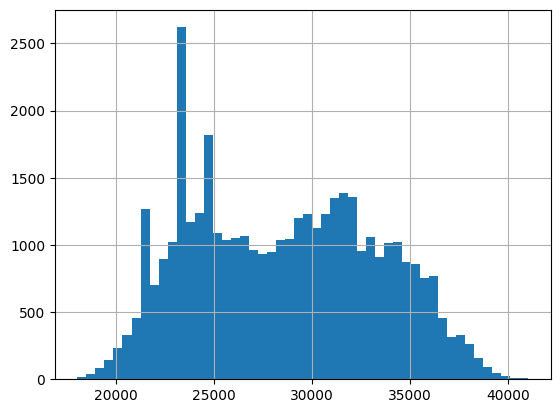

In [11]:
import matplotlib.pyplot as plt

y.hist(bins=50)
plt.show()

In [16]:
numeric_df = df.select_dtypes(include="number")

corr = numeric_df.corr()["power_consumption"]

corr.sort_values(ascending=False).head(20)

power_consumption          1.000000
Gotham City_wind_speed     0.217454
New New York_wind_speed    0.187813
Bedrock_wind_speed         0.171991
Paperopoli_rain_short      0.163391
Paperopoli_clouds          0.158239
Bedrock_t_low              0.158083
Bedrock_t                  0.136516
Paperopoli_wind_speed      0.135794
Bedrock_clouds             0.134016
New New York_clouds        0.126438
Springfield_wind_speed     0.120072
New New York_t             0.119660
Springfield_clouds         0.118186
New New York_t_high        0.117288
New New York_rain_short    0.114727
Bedrock_t_high             0.111436
Paperopoli_t_high          0.110462
New New York_t_low         0.109605
Gotham City_t_low          0.102688
Name: power_consumption, dtype: float64

In [17]:
for col in X.select_dtypes(include="object").columns:
    print(f"\n{col}")
    print(X[col].nunique())


Bedrock_weather_main
9

Bedrock_weather_description
24

Gotham City_weather_main
9

Gotham City_weather_description
34

New New York_weather_main
11

New New York_weather_description
30

Paperopoli_weather_main
9

Paperopoli_weather_description
31

Springfield_weather_main
9

Springfield_weather_description
33


C:\Users\hanis\AppData\Local\Temp\ipykernel_38284\2299503194.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in X.select_dtypes(include="object").columns:


In [18]:
for col in X.select_dtypes(include="object").columns:
    print(f"\n{col}")
    print(X[col].value_counts().head(10))


Bedrock_weather_main
Bedrock_weather_main
clouds          20257
clear           16296
rain             2637
thunderstorm      329
mist              267
drizzle           136
fog                68
smoke               6
haze                1
Name: count, dtype: int64

Bedrock_weather_description
Bedrock_weather_description
sky is clear               16296
few clouds                 12389
scattered clouds            4082
broken clouds               3403
light rain                  1777
moderate rain                556
overcast clouds              383
mist                         267
proximity thunderstorm       121
light intensity drizzle      119
Name: count, dtype: int64

Gotham City_weather_main
Gotham City_weather_main
clouds          18141
clear            8945
rain             7511
mist             2118
fog              1671
drizzle           777
snow              475
thunderstorm      287
haze               72
Name: count, dtype: int64

Gotham City_weather_description
Gotham City_

C:\Users\hanis\AppData\Local\Temp\ipykernel_38284\2403585673.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in X.select_dtypes(include="object").columns:


In [19]:
print("X duplicates:", X.duplicated().sum())

print(
    "Dataset duplicates:",
    df.duplicated().sum()
)

X duplicates: 9700
Dataset duplicates: 9274


In [20]:
print(df.index[:10])
print(df.index[-10:])

RangeIndex(start=0, stop=10, step=1)
RangeIndex(start=39987, stop=39997, step=1)
